Bitcoin = bitcoin, in group 1. Coins used: 606 of 615 (9 stablecoin-like coins left out)

Average similarity with Bitcoin, by group (* = built from the same information as the groups, so partly circular):
       coins  Copula: crash together*  HMM: same market mood*  GLASSO: direct link*  DTW: same shape*  Cointegration: long-run tie*  Composite (all five)*  Pearson (independent check)
group                                                                                                                                                                                  
1        231                    0.533                   0.736                 0.501             0.466                         0.006                  0.596                        0.569
2         49                    0.262                   0.373                 0.500             0.346                         0.008                  0.302                        0.254
3        117                    0.458                   0.6

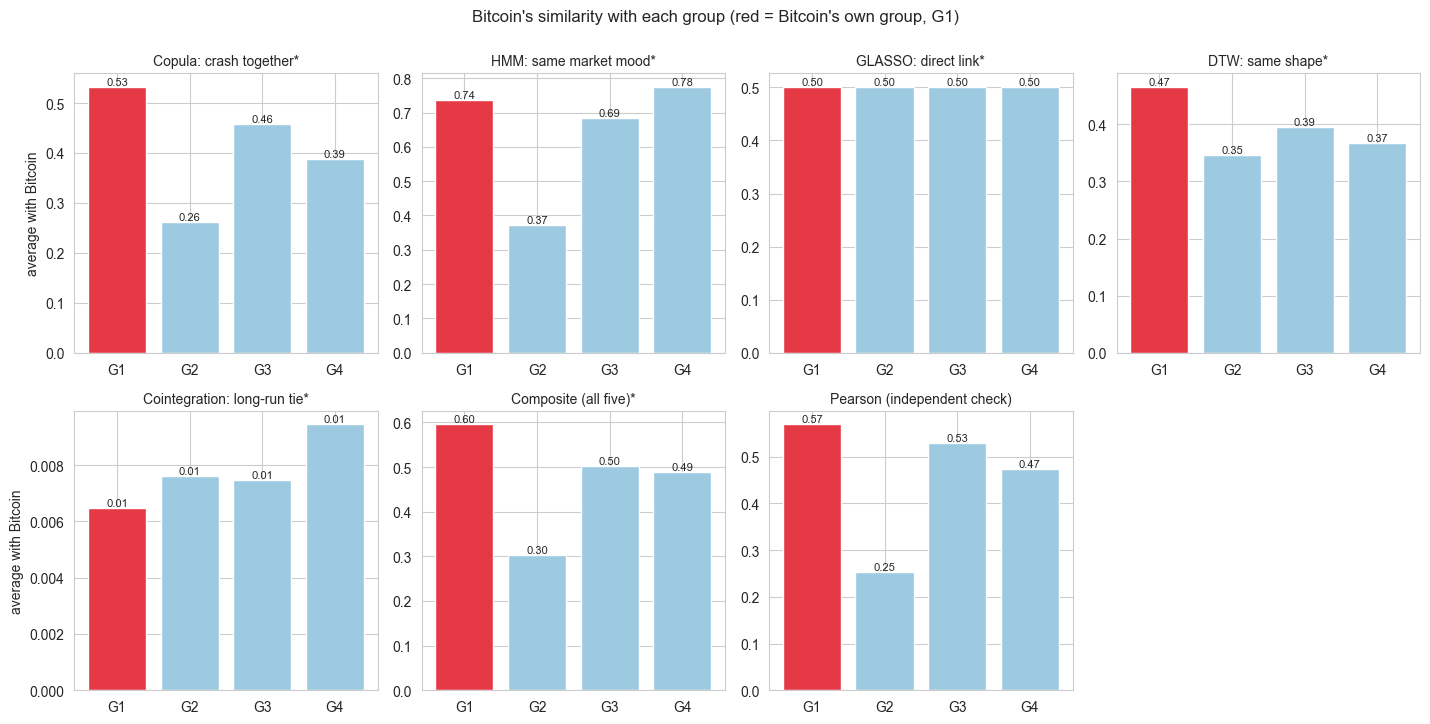

                     measure other_group  own_mean  other_mean    diff      p
     Copula: crash together*           2    0.5327      0.2616  0.2711 0.0000
     Copula: crash together*           3    0.5327      0.4582  0.0745 0.0000
     Copula: crash together*           4    0.5327      0.3877  0.1449 0.0000
     Copula: crash together*  all others    0.5327      0.3932  0.1394 0.0000
      HMM: same market mood*           2    0.7365      0.3735  0.3630 0.0000
      HMM: same market mood*           3    0.7365      0.6854  0.0510 0.0027
      HMM: same market mood*           4    0.7365      0.7751 -0.0387 1.0000
      HMM: same market mood*  all others    0.7365      0.6945  0.0420 0.7376
        GLASSO: direct link*           2    0.5012      0.5000  0.0012 0.0081
        GLASSO: direct link*           3    0.5012      0.5000  0.0012 0.0001
        GLASSO: direct link*           4    0.5012      0.5000  0.0012 0.0000
        GLASSO: direct link*  all others    0.5012      0.5000  

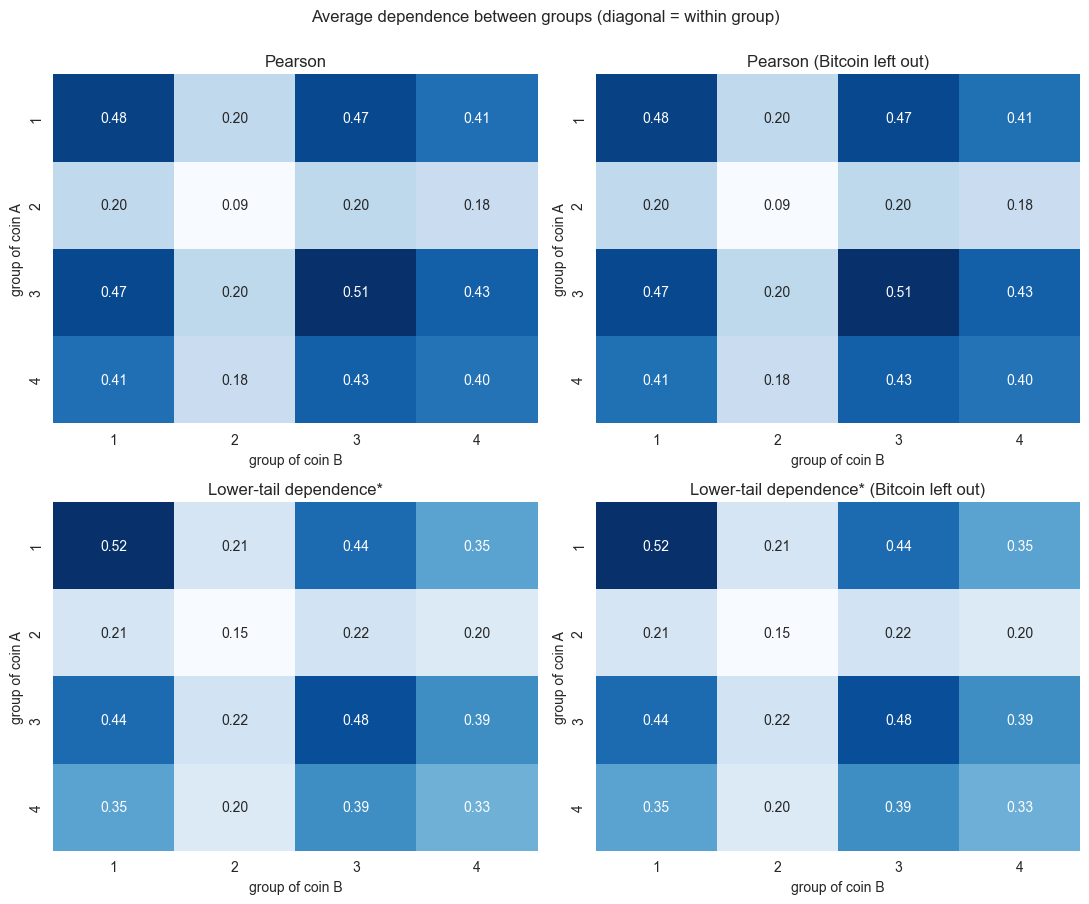

               measure  Bitcoin left out groups whose own group is highest in the row
               Pearson             False                                       2 of 4
               Pearson              True                                       2 of 4
Lower-tail dependence*             False                                       2 of 4
Lower-tail dependence*              True                                       2 of 4


In [1]:
# %% [markdown]
# # Bitcoin vs the four groups - is Bitcoin more dependent on coins in its own group?
#
# 1. For every other coin, take its similarity with Bitcoin from each of the five methods and the composite
#      (Bitcoin's row of each similarity matrix from Section 3.4):
#      Copula (crash together), HMM (same market mood), GLASSO (direct link), DTW (same shape of ups and downs),
#      Cointegration (long-run price tie) and the Composite. Optionally plain Pearson correlation as a reference.
#    The panels have different scales (each method scores differently), so compare the bars INSIDE a panel
#    (is Bitcoin's own group the highest?), not across panels.
#    CAUTION: the six measures marked * are the inputs of the groups, so this is in-sample. Pearson is the least
#      circular but is related (HMM and GLASSO are built from correlations). The clean test is a later period:
#      groups from the early years, dependence measured on the later years (points_2_to_5.py, point 4).
# 2. Average each measure by group (bar charts). Bitcoin's own group is red.
# 3. Test: is the own group higher than each other group? (one-sided Mann-Whitney on the coins' values)
# 4. Does the same hold for ALL coins and not only Bitcoin? A 4 x 4 table of average dependence between groups
#    (rows = group of coin A, columns = group of coin B). Diagonal highest in its row = coins depend most on their own group.
#    Repeated without Bitcoin.
# Coins that look like stablecoins (daily volatility under 1%) are left out of the comparisons,
# because their dependence with anything is meaningless. Set DROP_STABLE_LIKE = False to keep them.

# %%
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

for _base in [".", "research", ".."]:
    if os.path.isdir(os.path.join(_base, "similarity_outputs")):
        os.chdir(_base)
        break
else:
    raise FileNotFoundError("Could not find similarity_outputs/. Run from research/ or the project folder.")

SIM_DIR          = "similarity_outputs"
OUT              = "publication_outputs/bitcoin_by_group"
DATA_PATH        = "../data/crypto_with_indicators.parquet"
K                = 4
TAIL_Q           = 0.10
DROP_STABLE_LIKE = True
VOL_FLAG         = 0.01
PEERS_FROM_NOTES = ["BNB", "BCH", "AAVE", "ETH", "NEXO"]     # closest peers named in the thesis
INCLUDE_PEARSON  = True      # add plain Pearson correlation as an extra reference panel
os.makedirs(OUT, exist_ok=True)
sns.set_style("whitegrid")

# panel title -> similarity matrix file written by Section 3.4
SIM_FILES = {
    "Copula: crash together*":          "copula_ltdc_matrix.csv",
    "HMM: same market mood*":           "hmm_similarity_matrix.csv",
    "GLASSO: direct link*":             "glasso_similarity_matrix.csv",
    "DTW: same shape*":                 "dtw_similarity_matrix.csv",
    "Cointegration: long-run tie*":     "coint_similarity_matrix.csv",
    "Composite (all five)*":            "composite_similarity_matrix.csv",
}
sims = {name: pd.read_csv(f"{SIM_DIR}/{f}", index_col=0) for name, f in SIM_FILES.items()}
groups = pd.read_csv(f"{SIM_DIR}/cluster_assignments_K{K}.csv").set_index("coin_id")["cluster"]
coins = [c for c in sims["Composite (all five)*"].index if c in groups.index and all(c in m.index for m in sims.values())]
sims = {n: m.reindex(index=coins, columns=coins) for n, m in sims.items()}
groups = groups.loc[coins].astype(int)

import pyarrow.parquet as pq
avail = set(pq.ParquetFile(DATA_PATH).schema.names)
raw = pd.read_parquet(DATA_PATH, columns=[c for c in ["date", "coin_id", "symbol", "close", "market_cap_usd", "is_stablecoin"] if c in avail])
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[(raw["is_stablecoin"] == False) & raw["coin_id"].isin(coins)].sort_values(["coin_id", "date"])
raw["log_ret"] = raw.groupby("coin_id")["close"].transform(lambda x: np.log(x / x.shift(1)))
ret = raw.pivot_table(index="date", columns="coin_id", values="log_ret").reindex(columns=coins)
g_ = raw.groupby("coin_id")
meta = pd.DataFrame({"symbol": g_["symbol"].first(), "mc": g_["market_cap_usd"].last()}).reindex(coins)
BTC = meta["mc"].where(meta["symbol"].str.upper() == "BTC").idxmax()
own = groups[BTC]
vol = ret.std()
stable_like = vol.index[vol < VOL_FLAG]
use = [c for c in coins if not (DROP_STABLE_LIKE and c in stable_like)]
print(f"Bitcoin = {BTC}, in group {own}. Coins used: {len(use)} of {len(coins)}"
      + (f" ({len(stable_like)} stablecoin-like coins left out)" if DROP_STABLE_LIKE else ""))


# %% [markdown]
# ## 1. Dependence with Bitcoin, averaged by group

# %%
PEARSON = "Pearson (independent check)"
pairs = pd.DataFrame({name: m[BTC] for name, m in sims.items()}, index=coins)      # Bitcoin's row of each matrix
if INCLUDE_PEARSON:
    pairs[PEARSON] = ret.corrwith(ret[BTC])
pairs = pairs.drop(index=BTC).loc[[c for c in use if c != BTC]]
pairs["group"] = groups.loc[pairs.index]
measures = [c for c in pairs.columns if c != "group"]

by_group = pairs.groupby("group")[measures].mean()
by_group.insert(0, "coins", pairs["group"].value_counts().sort_index())
print("\nAverage similarity with Bitcoin, by group (* = built from the same information as the groups, so partly circular):")
print(by_group.round(3).to_string())
own_highest = [m for m in measures if by_group[m].idxmax() == own]
print(f"\nBitcoin's own group (G{own}) is the highest in {len(own_highest)} of {len(measures)} measures: {own_highest}")
by_group.to_csv(f"{OUT}/bitcoin_by_group.csv")

ncols = 4
nrows = int(np.ceil(len(measures) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.6 * nrows), squeeze=False)
for ax, m in zip(axes.flat, measures):
    vals = by_group[m]
    bars = ax.bar([f"G{g}" for g in vals.index], vals.values, color=["#e63946" if g == own else "#9ecae1" for g in vals.index])
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{b.get_height():.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(m, fontsize=10)
for ax in list(axes.flat)[len(measures):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("average with Bitcoin")
fig.suptitle(f"Bitcoin's similarity with each group (red = Bitcoin's own group, G{own})", y=1.0)
plt.tight_layout(); fig.savefig(f"{OUT}/bitcoin_by_group.png", dpi=150, bbox_inches="tight"); plt.show()


# %% [markdown]
# ## 2. Is the own group really higher? (own group vs each other group)
# diff = average over own-group coins minus average over the other group's coins.
# p = one-sided Mann-Whitney (small p = own group is higher). Measures marked * share information with the groups.

# %%
rows = []
for m in measures:
    a = pairs.loc[pairs["group"] == own, m].dropna()
    for g in sorted(pairs["group"].unique()):
        if g == own:
            continue
        b = pairs.loc[pairs["group"] == g, m].dropna()
        p = stats.mannwhitneyu(a, b, alternative="greater").pvalue if len(a) > 2 and len(b) > 2 else np.nan
        rows.append({"measure": m, "other_group": g, "own_mean": a.mean(), "other_mean": b.mean(), "diff": a.mean() - b.mean(), "p": p})
    b = pairs.loc[pairs["group"] != own, m].dropna()
    rows.append({"measure": m, "other_group": "all others", "own_mean": a.mean(), "other_mean": b.mean(),
                 "diff": a.mean() - b.mean(), "p": stats.mannwhitneyu(a, b, alternative="greater").pvalue})
tests = pd.DataFrame(rows)
tests.to_csv(f"{OUT}/bitcoin_own_vs_other.csv", index=False)
print(tests.round(4).to_string(index=False))

peers = pairs.loc[[c for c in pairs.index if meta.loc[c, "symbol"] in PEERS_FROM_NOTES]]
print("\nPeers named in the thesis notes: group and Pearson with Bitcoin")
peer_cols = {"symbol": meta.loc[peers.index, "symbol"], "group": peers["group"]}
peer_cols["Pearson"] = peers[PEARSON] if INCLUDE_PEARSON else ret[peers.index].corrwith(ret[BTC])
print(pd.DataFrame(peer_cols).round(3).to_string())


# %% [markdown]
# ## 3. Is it only Bitcoin? Dependence between groups for all coins
# Each cell = average dependence between a coin in the row group and a coin in the column group.
# The diagonal is the "within group" value. If the diagonal is the highest value in its row,
# coins depend most on coins in their own group. Shown for Pearson and lower-tail dependence (* = shares information with the groups),
# and with Bitcoin left out as a check that Bitcoin is not driving the result.

# %%
def lower_tail_matrix(r, q=TAIL_Q, min_obs=30):
    valid = r.notna()
    u = r.rank() / (valid.sum() + 1)
    ind = (u <= q).astype(float).values
    v = valid.astype(float).values
    nobs = v.T @ v
    m = (ind.T @ ind) / np.maximum(nobs, 1) / q
    m[nobs < min_obs] = np.nan
    np.fill_diagonal(m, 1.0)
    return pd.DataFrame(m, index=r.columns, columns=r.columns)


def block_means(M, lab):
    gl = sorted(set(lab.values))
    idx = {g: np.where(lab.values == g)[0] for g in gl}
    V = M.loc[lab.index, lab.index].values.copy()
    np.fill_diagonal(V, np.nan)
    return pd.DataFrame([[np.nanmean(V[np.ix_(idx[a], idx[b])]) for b in gl] for a in gl], index=gl, columns=gl)


r_use = ret[use]
mats = {"Pearson": r_use.corr(min_periods=30), "Lower-tail dependence*": lower_tail_matrix(r_use)}
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
summary = []
for row, (name, M) in enumerate(mats.items()):
    for col, excl in enumerate([False, True]):
        lab = groups.loc[use]
        if excl:
            lab = lab.drop(index=BTC)
        B = block_means(M, lab)
        highest = int((B.values.argmax(axis=1) == np.arange(len(B))).sum())
        summary.append({"measure": name, "Bitcoin left out": excl, "groups whose own group is highest in the row": f"{highest} of {len(B)}"})
        sns.heatmap(B, annot=True, fmt=".2f", cmap="Blues", ax=axes[row, col], cbar=False)
        axes[row, col].set_title(f"{name}{' (Bitcoin left out)' if excl else ''}")
        axes[row, col].set_xlabel("group of coin B"); axes[row, col].set_ylabel("group of coin A")
        B.to_csv(f"{OUT}/group_by_group_{name.split()[0].lower()}{'_noBTC' if excl else ''}.csv")
fig.suptitle("Average dependence between groups (diagonal = within group)", y=1.0)
plt.tight_layout(); fig.savefig(f"{OUT}/group_by_group.png", dpi=150, bbox_inches="tight"); plt.show()
print(pd.DataFrame(summary).to_string(index=False))